# 3D Computer Vision (2026/27) - Exercise Sheet 2

---

**Release:** 11.11.2026  
**Deadline:** 23.11.2026, 23:59  
**Exercise session:** 26.11.2026 (mandatory)

**Group:** add your group number  
**Members:** add your names

### Submission

Submit one `groupXX_exercise02.zip` in OLAT. It must contain a folder `groupXX_exercise02/` with your completed notebook, an HTML export showing all outputs, and the `data/` directory needed to run it. Use relative data paths. Install the packages from `requirements.txt` if needed.

By submitting, you confirm that all listed members contributed, no unlisted people were involved, and no solution content was copied from other people, large language models, websites, or other sources.

Attendance at the exercise session is mandatory. A group will be chosen at random to explain its solution. Be prepared to explain your work; failing to do so results in failing the task.

### Implementation

Complete the TODO cells using the models and derivations from the lecture slides. Implement the required vision steps yourself. NumPy operations, image I/O, plotting, and the provided utilities are allowed. Functions that compute the fundamental matrix, epipolar lines, or matches for you (such as `cv2.findFundamentalMat` or `cv2.computeCorrespondEpilines`) do not count as a solution.

---

# Theory Questions

## Task 1 — Epipolar lines

Cameras $C$ and $C'$ have the parameters below.

$$
\begin{aligned}
K=K'&=\begin{pmatrix}5&0&0\\0&5&0\\0&0&1\end{pmatrix},
& K^{-1}&=\begin{pmatrix}\frac15&0&0\\0&\frac15&0\\0&0&1\end{pmatrix},\\
R&=I,
& t&=\begin{pmatrix}0\\0\\2\end{pmatrix}.
\end{aligned}
$$

The extrinsics map from $C$ to $C'$, i.e. $\mathbf{\tilde X}'=\begin{pmatrix}{}_C^{C'}R & t_{C'}\\\mathbf{0_3}^\top & 1\end{pmatrix}\mathbf{\tilde X}$.

Find the epipolar line $l'$ in $C'$ for the pixel $u=(50,25)$ in $C$. Show your calculation.

If $u'$ lies on this line, does it have to match $u$? Explain.

TODO: answer task 1

Essential matrix $E$:

$$
E = [t]_\times R = [t]_\times I = \begin{bmatrix} 0 & -2 & 0 \\ 2 & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}
$$

Fundamental matrix $F = K'^{-T} E K^{-1}$:

$$
F = \begin{bmatrix} \frac{1}{5} & 0 & 0 \\ 0 & \frac{1}{5} & 0 \\ 0 & 0 & 1 \end{bmatrix}
\begin{bmatrix} 0 & -2 & 0 \\ 2 & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}
\begin{bmatrix} \frac{1}{5} & 0 & 0 \\ 0 & \frac{1}{5} & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

Calculate:

$$
= \begin{bmatrix} 0 & -\frac{2}{5} & 0 \\ \frac{2}{5} & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}
\begin{bmatrix} \frac{1}{5} & 0 & 0 \\ 0 & \frac{1}{5} & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

Final $F$:

$$
= \begin{bmatrix} 0 & -\frac{2}{25} & 0 \\ \frac{2}{25} & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}
$$

Compute epipolar line $l' = F \tilde{u}$:

$$
l' = \begin{bmatrix} 0 & -\frac{2}{25} & 0 \\ \frac{2}{25} & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}
\begin{bmatrix} 50 \\ 25 \\ 1 \end{bmatrix}
= \begin{bmatrix} -2 \\ 4 \\ 0 \end{bmatrix}
$$

Line equation:

$$
-2u' + 4v' = 0
$$

It doesn't have to match $u$. This is because the exact information of depth is unknown. Each position on this epipolar line $l'$ is possible.

## Task 2 — Homography matrix

Given is the following transformation of 2D points:
- no rotation,
- $4$ times scaling
- and translation by $5$ in y-direction and $-10$ in x-direction.

What is the homography matrix that represents this transformation?

TODO: answer task 2

Homography matrix:

$$
H = \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix}
$$

Given $\theta = 0^\circ$, scaling factor = 4:

$$
R = \begin{bmatrix} s(\cos 0^\circ) & s(-\sin 0^\circ) \\ s(\sin 0^\circ) & s(\cos 0^\circ) \end{bmatrix}
= \begin{bmatrix} 4 & 0 \\ 0 & 4 \end{bmatrix}
$$

Given translations:

$$
h_{13} = -10
$$

$$
h_{23} = 5
$$

Final homography matrix:

$$
H = \begin{bmatrix} 4 & 0 & -10 \\ 0 & 4 & 5 \\ 0 & 0 & 1 \end{bmatrix}
$$

## Task 3 — Euler angles

Rotate by $30^\circ$ about $x$, $0^\circ$ about $y$, and $90^\circ$ about $z$, in that order. 


Express this rotation as one 3D rotation matrix $R$.

TODO: answer task 3

Given the rotation matrices:

$$
R = R_x(30^\circ) \cdot R_y(0^\circ) \cdot R_z(90^\circ)
$$

Substitute the known matrices:

$$
= \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos 30^\circ & -\sin 30^\circ \\ 0 & \sin 30^\circ & \cos 30^\circ \end{bmatrix}
\begin{bmatrix} \cos 0^\circ & 0 & \sin 0^\circ \\ 0 & 1 & 0 \\ -\sin 0^\circ & 0 & \cos 0^\circ \end{bmatrix}
\begin{bmatrix} \cos 90^\circ & -\sin 90^\circ & 0 \\ \sin 90^\circ & \cos 90^\circ & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

Calculate the numerical values:

$$
= \begin{bmatrix} 1 & 0 & 0 \\ 0 & \frac{\sqrt{3}}{2} & -\frac{1}{2} \\ 0 & \frac{1}{2} & \frac{\sqrt{3}}{2} \end{bmatrix}
\begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}
\begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

Simplify:

$$
= \begin{bmatrix} 1 & 0 & 0 \\ 0 & \frac{\sqrt{3}}{2} & -\frac{1}{2} \\ 0 & \frac{1}{2} & \frac{\sqrt{3}}{2} \end{bmatrix}
\begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix}
$$

Final result:

$$
= \begin{bmatrix} 0 & -1 & 0 \\ \frac{\sqrt{3}}{2} & 0 & -\frac{1}{2} \\ \frac{1}{2} & 0 & \frac{\sqrt{3}}{2} \end{bmatrix}
$$

## Task 4 — Homography and fundamental matrix

For each of the following three cases, answer these two questions: Can one homography $H$ map all the points between the images? Does the camera motion give a non-zero fundamental matrix $F$?

1. The camera translates in a nonplanar scene.
2. The camera translates while viewing a flat surface.
3. The camera only rotates about its optical centre in a nonplanar scene.

For case 3, write $H$ using $K_1$, $K_2$, and $R$. Give $E$ and $F$.

TODO: answer task 4
| Cases | One homography for all visible points | Non-zero F |
| --- | --- | --- |
| 1. | no | yes |
| 2. | yes | yes |
| 3. | yes | no |

For case 3,
TODO

$H$ = $K_2$ R $K_1^{-1}$

$E$ = $[t]_\times$R = $0_{3\times3}$

$F$ = $K_2^{-T}$ $E$ $K_1^{-1}$ = $0_{3\times3}$

# Implementation Task - Epipolar lines and interest point matching

## Task Overview and Given Data

Your overall task in this exercise will be to compute and draw epipolar lines between views 00 and 01 and match the given interest points.

You will be given the following data:
- **9 color images** of the scene in `data/images/`
    - 8 Bit RGB per pixel
    - Each image rendered from a different position but with the same camera
    - The images are already **undistorted**
- 1 Dictionary containing **camera calibration parameters** in `data/camera_calibration.npy`
    - They belong to the camera that was used to render the RGB images
- 1 NumPy array containing **9 world-to-camera transformations** in `data/world_to_camera.npy`.
    - Shape `(9, 4, 4)`. Entry `i` maps world coordinates directly to camera coordinates for image `view_names[i]`.
    - The world frame is camera 00, so entry 0 is the identity matrix.
- **10 interest points** in view 00 and **12 candidate points** in view 01, given in the setup cell.
    - Some points have no match.

Note: Pixel coordinates use `(x, y)` (equivalently `(u, v)`). NumPy images are indexed as `[y, x]`.

The following cells provide the plotting utilities and load the data.

In [1]:
# Provided plotting helpers.

from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image

def line_segment(line, image_shape):
    """Clip an epipolar line to the image boundaries.

    Inputs:
        line: array-like, shape (3,), the coefficients (a, b, c).
        image_shape: tuple containing the image height and width.
    Output:
        A NumPy array with shape (2, 2), containing two endpoints in (x, y)
        order, or None if there is no visible line segment.
    """
    h, w = image_shape[:2]
    line = np.asarray(line, dtype=float)
    scale = np.max(np.abs(line))
    if not np.isfinite(line).all() or scale == 0:
        return None
    a, b, c = line / scale
    points = []
    if abs(b) > 1e-14:
        for x in [0., w-1.]:
            y = -(a*x+c)/b
            if -1e-8 <= y <= h-1+1e-8:
                points.append(np.array([x, np.clip(y, 0, h-1)]))
    if abs(a) > 1e-14:
        for y in [0., h-1.]:
            x = -(b*y+c)/a
            if -1e-8 <= x <= w-1+1e-8:
                points.append(np.array([np.clip(x, 0, w-1), y]))
    unique = []
    for p in points:
        if not any(np.linalg.norm(p-q) < 1e-7 for q in unique):
            unique.append(p)
    if len(unique) < 2:
        return None
    # Farthest pair also handles numerical corner duplicates safely.
    return max((np.stack([p,q]) for i,p in enumerate(unique) for q in unique[i+1:]),
               key=lambda pair: np.linalg.norm(pair[0]-pair[1]))

def show_points(ax, image, xy, ids, title):
    """Display an image and label the given points.

    Inputs:
        ax: Matplotlib axes on which to draw.
        image: NumPy array, shape (H, W, 3), the RGB image.
        xy: NumPy array, shape (N, 2), of pixel coordinates (x, y).
        ids: list of N point labels.
        title: string, the plot title.
    Output:
        Displays the labelled points on ax.
    """
    ax.imshow(image)
    ax.scatter(xy[:,0], xy[:,1], s=36, c='#ffdd33', edgecolors='black', linewidths=.7)
    for p, label in zip(xy, ids):
        ax.annotate(label, p, xytext=(5,5), textcoords='offset points', color='white',
                    fontsize=8, bbox=dict(facecolor='black', alpha=.7, pad=1))
    ax.set(title=title, xlim=(-.5,image.shape[1]-.5), ylim=(image.shape[0]-.5,-.5),
           xlabel='x [px]', ylabel='y [px]')

def plot_cost_matrix(cost, source_ids, target_ids):
    """Plot the mean epipolar distance for each pair of points.

    Inputs:
        cost: NumPy array, shape (N, M), of mean distances in pixels.
        source_ids: list of N point labels in view 00, one per row.
        target_ids: list of M candidate labels in view 01, one per column.
    Output:
        Displays a labelled heatmap of the cost matrix.
    """
    fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')
    heatmap = ax.imshow(cost, cmap='magma_r', aspect='auto', vmin=0, vmax=10)
    ax.set_xticks(range(len(target_ids)), labels=target_ids)
    ax.set_yticks(range(len(source_ids)), labels=source_ids)
    ax.set(xlabel='View 01 candidate', ylabel='View 00 point',
           title='Epipolar cost matrix')
    for (i, j), value in np.ndenumerate(cost):
        color = 'black' if value < 3 or not np.isfinite(value) else 'white'
        ax.text(j, i, f'{value:.1f}', ha='center', va='center', color=color, fontsize=8)
    fig.colorbar(heatmap, ax=ax, label='Distance [px]', extend='max')
    plt.show()


In [2]:
# Load the data.
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / 'data/camera_calibration.npy').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the pack and start Jupyter in exercise_02_2627/.')

DATA = ROOT / 'data'
calibration = np.load(DATA / 'camera_calibration.npy', allow_pickle=True).item()
assert calibration['image_space'] == 'undistorted'
f = float(calibration['focal_length_px'])
cx, cy = calibration['principal_point']
K = np.array([[f, 0., cx], [0., f, cy], [0., 0., 1.]])
image_paths = sorted((DATA / 'images').glob('*.png'))
view_names = [p.stem for p in image_paths]
# Images are already undistorted.
undistorted_images = np.stack([np.asarray(Image.open(p).convert('RGB'), dtype=float) / 255.
                               for p in image_paths])
world_to_camera = np.load(DATA / 'world_to_camera.npy', allow_pickle=False)
# Given interest points.
ids_a = ['A00', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
points_a = np.array([[219.0, 59.0], [338.0, 38.0], [373.0, 69.0], [362.0, 105.0], [359.0, 219.0], [515.0, 237.0], [615.0, 160.0], [713.0, 288.0], [422.1, 281.3], [422.1, 321.8]], dtype=float)
ids_b = ['B00', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B10', 'B11']
points_b = np.array([[743.0, 386.0], [527.0, 78.0], [376.4, 282.7], [746.0, 480.0], [629.0, 171.0], [467.0, 38.0], [510.0, 66.0], [342.0, 66.0], [693.0, 180.0], [541.0, 263.0], [334.0, 214.0], [377.1, 323.5]], dtype=float)
a, b = view_names.index('00'), view_names.index('01')
height, width = undistorted_images.shape[1:3]
print('Views:', view_names, '| image size:', (width, height))
print('K =\n', K)
print('Interest points:', len(points_a), 'source;', len(points_b), 'target')

Views: ['00', '01', '02', '03', '04', '05', '06', '07', '08'] | image size: (881, 551)
K =
 [[629.28571429   0.         440.        ]
 [  0.         629.28571429 275.        ]
 [  0.           0.           1.        ]]
Interest points: 10 source; 12 target


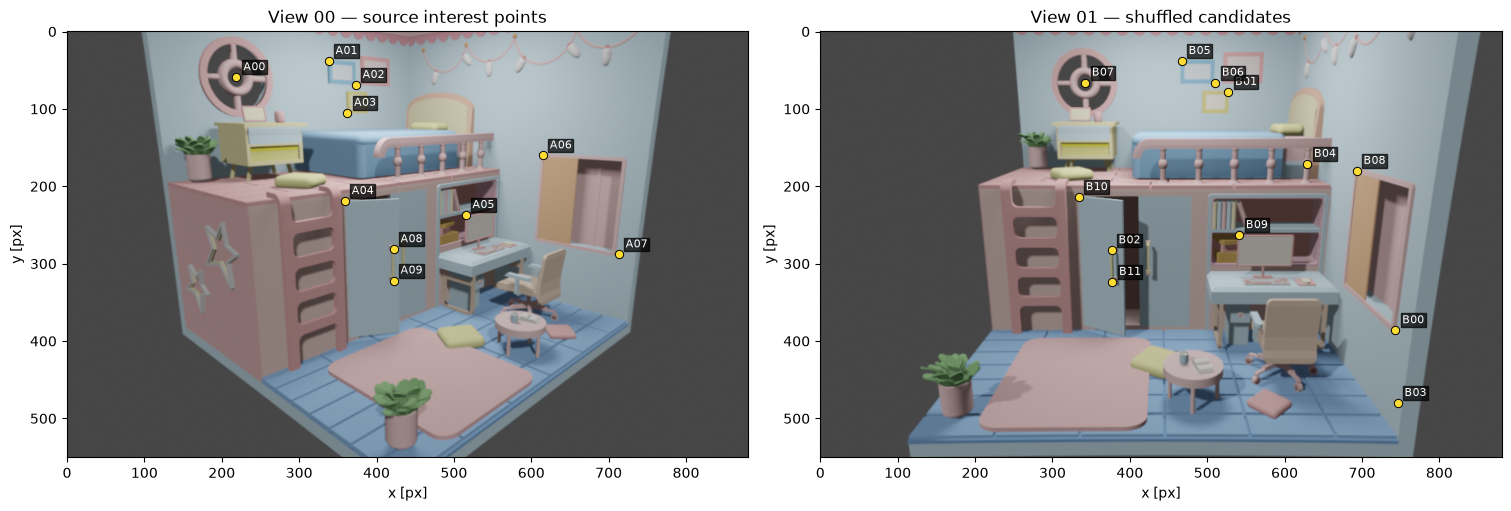

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
show_points(axes[0], undistorted_images[a], points_a, ids_a, 'View 00 — source interest points')
show_points(axes[1], undistorted_images[b], points_b, ids_b, 'View 01 — shuffled candidates')
plt.show()

## Task 1 — Compute and draw epipolar lines

Compute the fundamental matrix from the given camera parameters and plot the results for views 00 and 01. Keep your `F` variable. Task 2 will reuse it directly.

### 1.1 — Relative camera pose

Implement `relative_pose(T_w2a, T_w2b)` to compute the relative pose between two views from the two world-to-camera transformations. Return the rotation `R_a2b` and translation `t_b` such that

$$\mathbf{\tilde X}_b=\begin{pmatrix}{}^{b}_{a}R & \mathbf{t}_{b} \\ \mathbf{0_3}^\top & 1\end{pmatrix}\mathbf{\tilde X}_a.$$

Implement `skew(t)` to construct the 3×3 skew matrix $[\mathbf{t}]_\times$ satisfying $[\mathbf{t}]_\times\mathbf{v}=\mathbf{t}\times\mathbf{v}$.

In [4]:
def relative_pose(T_w2a, T_w2b):
    """Compute the relative pose from view a to view b.

    Inputs:
        T_w2a, T_w2b: NumPy arrays, shape (4, 4), mapping world coordinates
        to camera coordinates in views a and b.
    Output:
        R_a2b: NumPy array, shape (3, 3), the relative rotation.
        t_b: NumPy array, shape (3,), the relative translation.
        Together they map X_a to X_b = R_a2b @ X_a + t_b.
    """
    # TODO: compute the rotation and translation from view a to view b.
    #input values are w->a & w->b, we should transform 
    R_w2a = T_w2a[:3,:3]
    t_w2a = T_w2a[:3,-1]

    R_w2b = T_w2b[:3,:3]
    t_w2b = T_w2b[:3,-1]

    R_a2b = R_w2b @ R_w2a.T
    t_b = t_w2b - R_a2b @ t_w2a
    return R_a2b,t_b

In [7]:
def skew(t):
    """Build the cross-product matrix for t.

    Inputs:
        t: NumPy array, shape (3,).
    Output:
        A NumPy array with shape (3, 3) such that skew(t) @ v equals
        the cross product of t and v.
    """
    # TODO: construct the cross-product matrix.
    x,y,z = t
    skew_t = np.array([
        [0,-z,y],
        [z,0,-x],
        [-y,x,0]
    ])
    return skew_t

### 1.2 — Fundamental matrix

Implement `fundamental_from_poses(K_a, K_b, T_w2a, T_w2b)` to construct the 3×3 fundamental matrix from the supplied camera parameters. Print the result.

In [8]:
def fundamental_from_poses(K_a, K_b, T_w2a, T_w2b):
    """Build the fundamental matrix for views a and b.

    Inputs:
        K_a, K_b: NumPy arrays, shape (3, 3), the camera intrinsic matrices.
        T_w2a, T_w2b: NumPy arrays, shape (4, 4), the world-to-camera transformations.
    Output:
        F_a2b: floating-point NumPy array, shape (3, 3), mapping homogeneous
        pixel points in view a to epipolar lines in view b.
    """
    # TODO: compute the fundamental matrix from the supplied parameters.
    #calculate params for E
    R_a2b,t_b = relative_pose(T_w2a, T_w2b)
    E = skew(t_b) @ R_a2b
    #F = K_2 ^(-T) E K_1 ^(-1)
    F_a2b = np.linalg.inv(K_b).T @ E @ np.linalg.inv(K_a)
    return F_a2b

In [9]:
F = fundamental_from_poses(K, K, world_to_camera[a], world_to_camera[b])
print(F)

[[ 1.05126491e-22 -2.43920349e-06  2.59490763e-04]
 [-3.44955466e-06  1.08316070e-07  6.00094387e-03]
 [ 3.66975356e-04 -3.70558337e-03 -2.45414116e-01]]


### 1.3 — Epipolar lines

Given a point in one view, compute the corresponding epipolar line in the other view. Implement this as `epipolar_lines(points_xy, F)`. Return an array with shape `(N, 3)`, with each row storing the coefficients `(a, b, c)` of $au+bv+c=0$.

Use `F` for view 00 → 01 and `F.T` for view 01 → 00.

In [10]:
def epipolar_lines(points_xy, F):
    """Compute epipolar lines for points in the source view.

    Inputs:
        points_xy: NumPy array, shape (N, 2), of source pixel coordinates (u, v).
        F: NumPy array, shape (3, 3), mapping source points to target lines.
    Output:
        A floating-point NumPy array with shape (N, 3). Row i contains
        the coefficients (a, b, c) of the line for points_xy[i].
    """
    # TODO: compute the line coefficients for the source points.
    points_homo = np.concatenate([points_xy,np.ones_like(points_xy[:,:1])],axis=1) #(N,2)+ones(N,1)->(N,3)
    return (F @ points_homo.T).T  #return (N,3)

### 1.4 — Plot your results

Create a labelled figure for each direction. Show five source points for each view (images 00 and 01) and their corresponding epipolar lines in the other view (images 01 and images 00). Use the same color and label for each point and its line.

Use the provided `line_segment` with your line coefficients.

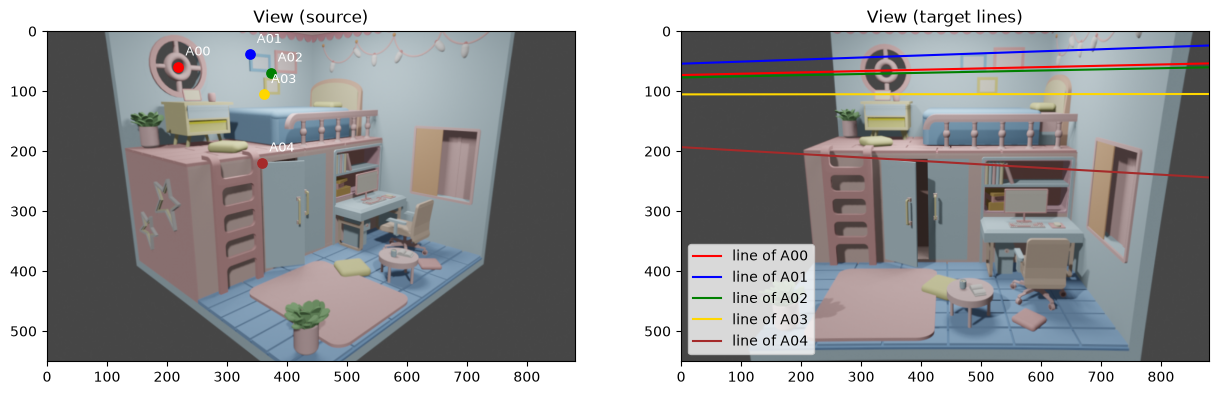

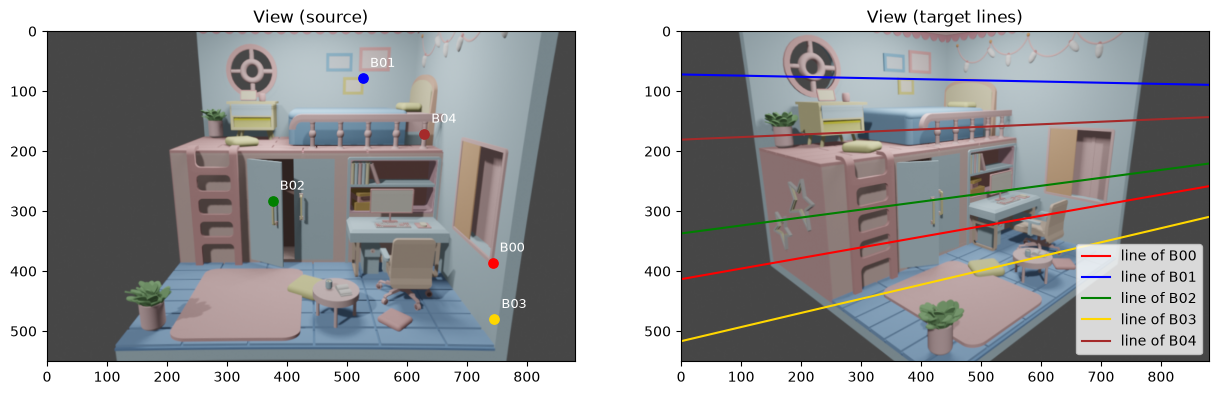

In [14]:
# TODO: plot five source points and their epipolar lines for each direction.

def draw_epipolar_lines(source_point, F, images,ids_source):
    figs, axs = plt.subplots(1,2,figsize=(15, 10))
    line_00 = epipolar_lines(source_point,F)
    colors = ['red','blue','green','gold','brown']
    axs[0].imshow(images[0])
    axs[0].set_title('View (source)')
    for (x,y),color,ids in zip(source_point,colors,ids_source[:5]):
        axs[0].scatter(x,y,c=color,s=45)
        axs[0].annotate(ids,(x,y),
                xytext=(5, 8),
                textcoords='offset points',
                color='white',
                fontsize=9)

    axs[1].imshow(images[1])
    axs[1].set_title('View (target lines)')
    for l,color,ids in zip(line_00,colors,ids_source[:5]):
        p = line_segment(l,(height,width))
        if p is not None:
            axs[1].plot(p[:,0],p[:,1],c=color,label=f'line of {ids}')
    axs[1].legend()
    plt.show()

draw_epipolar_lines(points_a[:5], F, [undistorted_images[a],undistorted_images[b]], ids_a)
draw_epipolar_lines(points_b[:5], F.T, [undistorted_images[b],undistorted_images[a]], ids_b)

## Task 2 — Match the given interest points

Use the given **`undistorted_images`** and **`F` from Task 1** as the image backgrounds and fundamental matrix. Match the points using their coordinates and epipolar distances. Point IDs and row order do not indicate a match.

### 2.1 — Point-to-line distances

Implement `point_line_distances(points_xy, lines)` to compute the distance from each point to each line. For a point $(u,v)$ and a line with coefficients $(a,b,c)$, use

$$d=\frac{|au+bv+c|}{\sqrt{a^2+b^2}}.$$

Return an array with shape `(number_of_lines, number_of_points)`.

Implement `symmetric_epipolar_cost(points_a, points_b, F_a2b)` to compute the mean of the forward and reverse distances for each pair. Return a cost matrix of shape `(len(points_a), len(points_b))`.

Use the provided `plot_cost_matrix(cost, ids_a, ids_b)` to plot the costs. Each row represents a point in view 00 and each column represents a candidate in view 01. The colors saturate at 10 pixels.

In [15]:
def point_line_distances(points_xy, lines):
    """Compute the perpendicular distance from each point to each line.

    Inputs:
        points_xy: NumPy array, shape (P, 2), of pixel coordinates (u, v).
        lines: NumPy array, shape (L, 3), of line coefficients (a, b, c)
        in the same image coordinates.
    Output:
        A floating-point NumPy array with shape (L, P), where L is the
        number of lines and P is the number of points. Entry [i, j] is
        the distance in pixels from points_xy[j] to lines[i].
    """
    # TODO: compute the distance from each point to each line.
    points_homo = np.hstack([points_xy,np.ones_like(points_xy[:,:1])])
    numerator = lines @ points_homo.T
    denominator = np.sqrt(lines[:,0]**2+lines[:,1]**2)
    return np.abs(numerator) / denominator[:,np.newaxis]

In [16]:
def symmetric_epipolar_cost(points_a, points_b, F_ba):
    """Compute the mean of the two point-to-line distances for each pair.

    Inputs:
        points_a: NumPy array, shape (N, 2), of N pixel points in view a.
        points_b: NumPy array, shape (M, 2), of M pixel points in view b.
        F_ba: NumPy array, shape (3, 3), mapping points in view a to lines in view b.
    Output:
        A floating-point cost matrix with shape (N, M). Entry [i, j]
        averages the two perpendicular distances for points_a[i] and
        points_b[j]. Both distances use undistorted pixel coordinates.
    """
    # TODO: combine the distances from both views.
    #calculate vertical distance of points and epipolar lines in view b 
    lines_inB = epipolar_lines(points_a,F_ba)
    dist_b = point_line_distances(points_b,lines_inB)

    lines_inA = epipolar_lines(points_b,F_ba.T)
    dist_a = point_line_distances(points_a,lines_inA)

    return (dist_b + dist_a.T)/2

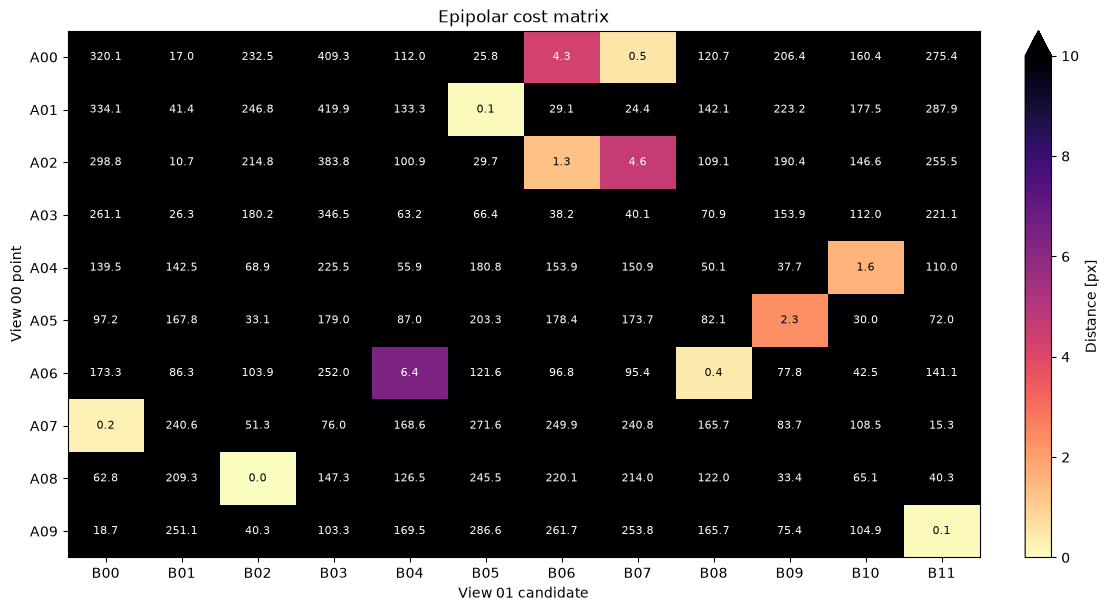

In [17]:
cost = symmetric_epipolar_cost(points_a, points_b, F)
plot_cost_matrix(cost, ids_a, ids_b)


### 2.2 — Match the points

Implement `match_mutual(cost, tau_px=3.0, margin_px=1.0)`. For each point, find the candidate with the smallest cost. Keep a pair if:

1. Each point is the other's closest candidate.
2. The cost is at most `tau_px`.
3. The next-best cost is at least `margin_px` larger in both views.

Return a list of `(source_row, target_row, cost)` tuples in source-row order. Leave the other points unmatched.

In [30]:
def match_mutual(cost, tau_px=3.0, margin_px=1.0):
    """Find pairs of interest points that satisfy the matching criteria.

    Inputs:
        cost: NumPy array with N rows for source points and M columns
        for target candidates. Entries are mean epipolar distances in pixels.
        tau_px: float, the maximum cost of an accepted match in pixels.
        margin_px: float, the minimum gap to the next-best cost in either view.
    Output:
        A list of (source_row, target_row, cost) tuples in source-row order.
    """
    # TODO: find the matches and return them in source-row order.
    #find the index of best cost and values of second-best cost
    amb = np.argmin(cost,axis=1)
    bma = np.argmin(cost,axis=0)
    row_sorted = np.sort(cost,axis=1)
    col_sorted = np.sort(cost,axis=0)
    a_second_min = row_sorted[:,1]
    b_second_min = col_sorted[1,:]
    match = []
    for i in range(cost.shape[0]):
        j = amb[i]
        c = float(cost[i,j])
        #ensure 1.each point is the other's closest candidate, 2.cost is at most tau_px 3.next-best cost is at leat margin_px larger
        if bma[j] == i and c<=tau_px and a_second_min[i]-c>=margin_px and b_second_min[j]-c>=margin_px:

            match.append((i,int(j),c))
    
    return match

match = match_mutual(cost)

### 2.3 — Plot the matches

Print the matched target and distance for each source point. Mark points without a match as `unmatched`.

Overlay the points on the two undistorted images and connect the matches. Use the same color for each match in both views. Label the points and mark unmatched points. Check that the matches refer to the same features.

source point:A00, matched target:B07, distance:0.5
source point:A01, matched target:B05, distance:0.1
source point:A02, matched target:B06, distance:1.3
source point:A04, matched target:B10, distance:1.6
source point:A05, matched target:B09, distance:2.3
source point:A06, matched target:B08, distance:0.4
source point:A07, matched target:B00, distance:0.2
source point:A08, matched target:B02, distance:0.0
source point:A09, matched target:B11, distance:0.1
unmatched points in A:
source point:A03 is unmatched
unmatched points in B:
target point:B01 is unmatched
target point:B03 is unmatched
target point:B04 is unmatched


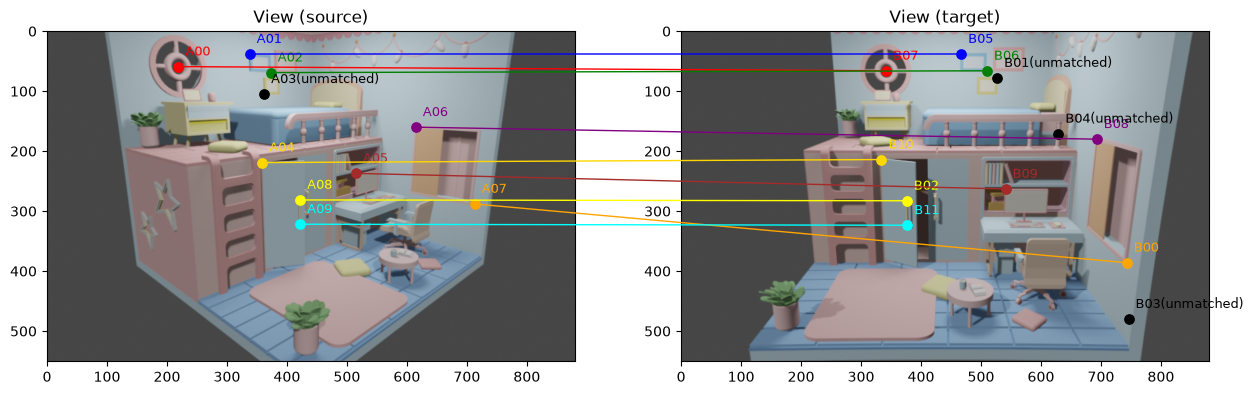

In [50]:
# TODO: match the interest points and print the results.
for i,j,cost in match:
    print(f'source point:{ids_a[i]}, matched target:{ids_b[j]}, distance:{cost:.1f}')
    
print('unmatched points in A:')
matched_a = [m[0] for m in match]
for i in range(len(points_a)):
    if i not in matched_a:
        print(f'source point:{ids_a[i]} is unmatched')
        
print('unmatched points in B:')
matched_b = [m[1] for m in match]
for j in range(len(points_b)):
    if j not in matched_b:
        print(f'target point:{ids_b[j]} is unmatched')

# TODO: plot the matches on the two images.
from matplotlib.patches import ConnectionPatch
fig, ax = plt.subplots(1,2,figsize=(15, 10))
colors = ['red', 'blue', 'green', 'gold', 'brown', 'purple', 'orange', 'yellow', 'cyan']
ax[0].imshow(undistorted_images[a])
ax[0].set_title('View (source)')
ax[1].imshow(undistorted_images[b])
ax[1].set_title('View (target)')
#draw matched points and connection lines
for idx, (i,j,cost) in enumerate(match):
    color = colors[idx%len(colors)]
    #get coordinate
    p_a = points_a[i]
    p_b = points_b[j]

    #draw points and write labels
    ax[0].scatter(p_a[0],p_a[1],c=color,s=45)
    ax[0].annotate(ids_a[i],(p_a[0],p_a[1]),
                   xytext=(5, 8), #offset
                   textcoords='offset points',
                   color=color,
                   fontsize=9)
    
    ax[1].scatter(p_b[0],p_b[1],c=color,s=45)
    ax[1].annotate(ids_b[j],(p_b[0],p_b[1]),
                   xytext=(5, 8), #offset
                   textcoords='offset points',
                   color=color,
                   fontsize=9)

    #draw connection lines
    con = ConnectionPatch(xyA=p_a,xyB=p_b,
                          coordsA="data",
                          coordsB="data",
                          axesA=ax[0], #subplot of start point
                          axesB=ax[1], #subplot of end point
                          color=color,
                          zorder=10)
    fig.add_artist(con)

#draw unmatched points
for i in range(len(points_a)):
    if i not in matched_a:
        p_a = points_a[i]
        ax[0].scatter(p_a[0],p_a[1],c='black',s=45)
        ax[0].annotate(f'{ids_a[i]}(unmatched)',(p_a[0],p_a[1]),
                       xytext=(5, 8), #offset
                       textcoords='offset points',
                       color='black',
                       fontsize=9)

for j in range(len(points_b)):
    if j not in matched_b:
        p_b = points_b[j]
        ax[1].scatter(p_b[0],p_b[1],c='black',s=45)
        ax[1].annotate(f'{ids_b[j]}(unmatched)',(p_b[0],p_b[1]),
                       xytext=(5, 8), #offset
                       textcoords='offset points',
                       color='black',
                       fontsize=9)
plt.show()